# Лабораторная работа 3: Статистическое оценивание параметров и тестирование адекватности регрессионных моделей для используемых переменных.

- Выберите один из признаков как целевой и постройте регрессионную модель (Тип ириса тоже можно учесть).
- Для построенной модели проведите тесты Стьюдента (для значимости каждого коэффициента) и Фишера (для значимости всей модели).
- Проведите анализ остатков на нормальность и независимость.
- Все основные расчеты реализуйте сами, без готовых библиотечных функций

Король Денис, 3 курс, 8а группа  
Вариант: sepalwid

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as sts
from IPython.display import Image, display
import seaborn as sns

## Чтение данных из файла и формирование выборки

In [2]:
data = pd.read_excel('irisdat.xlsx')
print(data.shape)
data.head(3)

(150, 5)


,sepallen,sepalwid,petallen,petalwid,type
0,5.0,3.3,1.4,0.2,1
1,6.4,2.8,5.6,2.2,3
2,6.5,2.8,4.6,1.5,2


Проверка пропусков

In [3]:
data.isna()

,sepallen,sepalwid,petallen,petalwid,type
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
145,False,False,False,False,False
146,False,False,False,False,False
147,False,False,False,False,False
148,False,False,False,False,False


In [4]:
data.isna().sum(axis=0)

sepallen    0
sepalwid    0
petallen    0
petalwid    0
type        0
dtype: int64

Формирование выборки данных для варианта: sepalwid

## 1. Формирование переменных модели (учет типа ириса)

В качестве эндогенной (зависимой) переменной выбрана ширина чашелистика: $Y = \text{sepalwid}$.
В качестве объясняющих (экзогенных) переменных выступают:
* $x_1 = \text{sepallen}$ (длина чашелистика);
* $x_2 = \text{petallen}$ (длина лепестка);
* $x_3 = \text{petalwid}$ (ширина лепестка);
* Категориальный признак $\text{type} \in \{1, 2, 3\}$.

Чтобы избежать строгой мультиколлинеарности (ловушки фиктивных переменных), для 3 категорий вводим $3 - 1 = 2$ бинарные (дамми) переменные, принимая `type = 1` за базовый уровень:
* $x_4 = d_2 = \mathbb{I}(\text{type} = 2)$;
* $x_5 = d_3 = \mathbb{I}(\text{type} = 3)$.

Уравнение модели МЛР (обобщение формулы 7.12, стр. 94 конспекта [стр. 33 PDF]):
$$y_i = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + \beta_3 x_{i3} + \beta_4 d_{i2} + \beta_5 d_{i3} + \xi_i, \quad i = 1, \dots, n.$$


In [5]:
y = data['sepalwid'].values.astype(float)
n = len(y)

x1 = data['sepallen'].values.astype(float)
x2 = data['petallen'].values.astype(float)
x3 = data['petalwid'].values.astype(float)
d2 = (data['type'].values == 2).astype(float)
d3 = (data['type'].values == 3).astype(float)

# Матрица регрессоров X (первый столбец из единиц для свободного члена beta_0)
X = np.column_stack([np.ones(n), x1, x2, x3, d2, d3])
feature_names = ['Intercept (beta_0)', 'sepallen (beta_1)', 'petallen (beta_2)', 
                 'petalwid (beta_3)', 'type_2 (beta_4)', 'type_3 (beta_5)']

p = X.shape[1]  # число оцениваемых параметров (p = 6, число факторов k = p - 1 = 5)
print(f"Объем выборки n = {n}, число параметров модели p = {p}")


Объем выборки n = 150, число параметров модели p = 6


## 2. Оценивание параметров модели методом наименьших квадратов (МНК)

* **Формула МНК-оценок** (обобщение задачи 7.14–7.15, стр. 96–97 конспекта [стр. 35–36 PDF]):
  $$\hat{\beta} = (X^T X)^{-1} X^T y$$
* **Прогнозные значения и остатки** (формулы 7.16–7.17, стр. 97 конспекта [стр. 36 PDF]):
  $$\hat{y} = X\hat{\beta}, \quad e_i = \hat{\xi}_i = y_i - \hat{y}_i$$
* **Сумма квадратов остатков ($RSS$), полная сумма квадратов ($TSS$), несмещенная оценка дисперсии ошибок ($\hat{\sigma}^2$) и коэффициент детерминации ($R^2$)** (формулы 7.18–7.23, стр. 97–98 конспекта [стр. 36–37 PDF]):
  $$RSS = \sum_{i=1}^n (y_i - \hat{y}_i)^2, \quad TSS = \sum_{i=1}^n (y_i - \bar{y})^2, \quad \hat{\sigma}^2 = \frac{RSS}{n - p}, \quad R^2 = 1 - \frac{RSS}{TSS}$$


из Малюгин В.И._МСАДЭ_МУ

In [6]:
# Оценка вектора параметров beta
XTX_inv = np.linalg.inv(X.T @ X)
beta_hat = XTX_inv @ (X.T @ y)

# Прогнозные значения и остатки
y_hat = X @ beta_hat
residuals = y - y_hat

# Показатели качества модели
RSS = np.sum(residuals ** 2)
TSS = np.sum((y - np.mean(y)) ** 2)
ESS = TSS - RSS  # объясненная сумма квадратов
sigma2_hat = RSS / (n - p)
sigma_hat = np.sqrt(sigma2_hat)
R2 = 1.0 - RSS / TSS
R2_adj = 1.0 - (1.0 - R2) * (n - 1) / (n - p)

print("Оценки коэффициентов модели:")
for name, b in zip(feature_names, beta_hat):
    print(f"  {name:<20}: {b:.6f}")

print(f"\nRSS = {RSS:.6f}")
print(f"TSS = {TSS:.6f}")
print(f"Оценка стандартного отклонения ошибок sigma_hat = {sigma_hat:.6f}")
print(f"Коэффициент детерминации R^2 = {R2:.6f}")
print(f"Скорректированный R^2_adj = {R2_adj:.6f}")


Оценки коэффициентов модели:
  Intercept (beta_0)  : 1.657164
  sepallen (beta_1)   : 0.377773
  petallen (beta_2)   : -0.187567
  petalwid (beta_3)   : 0.625710
  type_2 (beta_4)     : -1.160285
  type_3 (beta_5)     : -1.398255

RSS = 10.327473
TSS = 28.306933
Оценка стандартного отклонения ошибок sigma_hat = 0.267803
Коэффициент детерминации R^2 = 0.635161
Скорректированный R^2_adj = 0.622493


## 3. Проверка статистической значимости коэффициентов ($t$-тест) и модели в целом ($F$-тест)

### 3.1. Проверка значимости отдельных коэффициентов ($t$-критерий Стьюдента)
Для каждого параметра $\beta_j$ ($j = 0, \dots, 5$) на уровне значимости $\varepsilon = 0.05$ проверяется гипотеза $H_0: \beta_j = 0$ при альтернативе $H_1: \beta_j \neq 0$ (формулы 7.24–7.26, стр. 98–99 конспекта [стр. 37–38 PDF]).
Ковариационная матрица оценок параметров имеет вид $\widehat{\text{Cov}}(\hat{\beta}) = \hat{\sigma}^2 (X^T X)^{-1}$, откуда стандартная ошибка $j$-го коэффициента: $SE(\hat{\beta}_j) = \sqrt{\hat{\sigma}^2 [(X^T X)^{-1}]_{jj}}$.
Статистика критерия (имеет распределение Стьюдента с $n - p$ степенями свободы):
$$t_j = \frac{\hat{\beta}_j}{SE(\hat{\beta}_j)}, \quad P_j = 2(1 - F_{t_{n-p}}(|t_j|)).$$
Гипотеза $H_0$ отклоняется, если $|t_j| \ge \Delta(\varepsilon)$ или $P_j \le \varepsilon$ (формула 2.333, стр. 71 конспекта [стр. 2 PDF]).

### 3.2. Проверка значимости модели в целом ($F$-критерий Фишера)
Проверяется гипотеза $H_0: \beta_1 = \beta_2 = \beta_3 = \beta_4 = \beta_5 = 0$ ($R^2 = 0$) с помощью $F$-статистики (с $k = p - 1$ и $n - p$ степенями свободы):
$$F = \frac{R^2 / (p - 1)}{(1 - R^2) / (n - p)} = \frac{ESS / (p - 1)}{RSS / (n - p)}, \quad P_F = 1 - F_{F_{p-1, n-p}}(F).$$


In [7]:
alpha = 0.05
df_res = n - p      # 144 степени свободы
df_reg = p - 1      # 5 степеней свободы

# Ковариационная матрица оценок и стандартные ошибки
cov_beta = sigma2_hat * XTX_inv
se_beta = np.sqrt(np.diag(cov_beta))

# t-статистики и p-значения
t_stats = beta_hat / se_beta
t_crit = sts.t.ppf(1 - alpha / 2, df=df_res)
p_vals_t = 2 * (1 - sts.t.cdf(np.abs(t_stats), df=df_res))

print(f"Критическое значение t_crit (df={df_res}, alpha={alpha}): {t_crit:.6f}\n")
print(f"{'Параметр':<20} | {'Оценка':>10} | {'Std.Err':>10} | {'t-stat':>10} | {'p-value':>10} | {'Значим?'}")
print("-" * 80)
for name, b, se, t_val, p_val in zip(feature_names, beta_hat, se_beta, t_stats, p_vals_t):
    is_sig = "Да" if p_val <= alpha else "Нет"
    print(f"{name:<20} | {b:10.5f} | {se:10.5f} | {t_val:10.5f} | {p_val:10.6f} | {is_sig}")

# F-тест Фишера
F_stat = (R2 / df_reg) / ((1 - R2) / df_res)
F_crit = sts.f.ppf(1 - alpha, dfn=df_reg, dfd=df_res)
p_val_F = 1 - sts.f.cdf(F_stat, dfn=df_reg, dfd=df_res)

print("\n--- F-тест Фишера для модели в целом ---")
print(f"F_stat = {F_stat:.6f}, F_crit = {F_crit:.6f}, p-value = {p_val_F:.6e}")
print(f"Модель в целом статистически значима: {p_val_F <= alpha}")


Критическое значение t_crit (df=144, alpha=0.05): 1.976575

Параметр             |     Оценка |    Std.Err |     t-stat |    p-value | Значим?
--------------------------------------------------------------------------------
Intercept (beta_0)   |    1.65716 |    0.25595 |    6.47467 |   0.000000 | Да
sepallen (beta_1)    |    0.37777 |    0.06557 |    5.76147 |   0.000000 | Да
petallen (beta_2)    |   -0.18757 |    0.08349 |   -2.24650 |   0.026194 | Да
petalwid (beta_3)    |    0.62571 |    0.12338 |    5.07156 |   0.000001 | Да
type_2 (beta_4)      |   -1.16029 |    0.19329 |   -6.00268 |   0.000000 | Да
type_3 (beta_5)      |   -1.39825 |    0.27715 |   -5.04519 |   0.000001 | Да

--- F-тест Фишера для модели в целом ---
F_stat = 50.138932, F_crit = 2.277044, p-value = 0.000000e+00
Модель в целом статистически значима: True


## 4. Анализ остатков на нормальность

В соответствии с **Разделом 6** конспекта (стр. 81–94 [стр. 12–25 PDF]) анализ нормальности проводится в два этапа:
1. **Разведочный анализ (стр. 84–89 конспекта [стр. 15–20 PDF]):**
   * Дескриптивные статистики: сравнение среднего $\bar{e}$ и медианы $M$, вычисление коэффициентов асимметрии ($A$) и эксцесса ($E$), проверка «правила 3-сигм» (ожидается $\approx 99.73\%$ наблюдений в границах $\pm 3\hat{\sigma}$) и «правила квартилей» ($IQR \approx 1.349\hat{\sigma}$).
   * Графический анализ: гистограмма с наложенной плотностью нормального распределения $N(0, \hat{\sigma}^2)$, график «ящик с усами» и график «квантиль–квантиль» (Q-Q plot, стр. 88–89 конспекта [стр. 19–20 PDF]), где теоретические квантили $z_i = \Phi^{-1}\left(\frac{i - 0.5}{n}\right)$ сопоставляются с упорядоченными нормированными остатками $e_{(i)} / \hat{\sigma}$.
2. **Подтверждающий анализ (стр. 72–74 конспекта [стр. 3–5 PDF]):**
   * Критерий согласия $\chi^2$ Пирсона (формулы 2.38–2.46): разбиваем область значений на $K$ интервалов, считаем эмпирические частоты $\nu_k$ и теоретические вероятности $p_k = F_0(a_k) - F_0(a_{k-1})$, вычисляем статистику $\chi^2_n = \sum_{k=1}^K \frac{(\nu_k - n p_k)^2}{n p_k}$ с числом степеней свободы $df = K - 1 - r$ (где $r=1$ — число оцененных параметров распределения $\sigma$, так как $\bar{e} = 0$).


--- Дескриптивный анализ остатков ---
Среднее: -8.930930e-14, Медиана: 0.004408
Станд. отклонение: 0.263272, IQR: 0.333298 (ожидаемое по норме 1.349*sigma = 0.361267)
Асимметрия: -0.355785, Эксцесс: 1.112384
Доля в +-1*sigma: 73.33% (норма 68.27%)
Доля в +-2*sigma: 95.33% (норма 95.45%)
Доля в +-3*sigma: 99.33% (норма 99.73%)


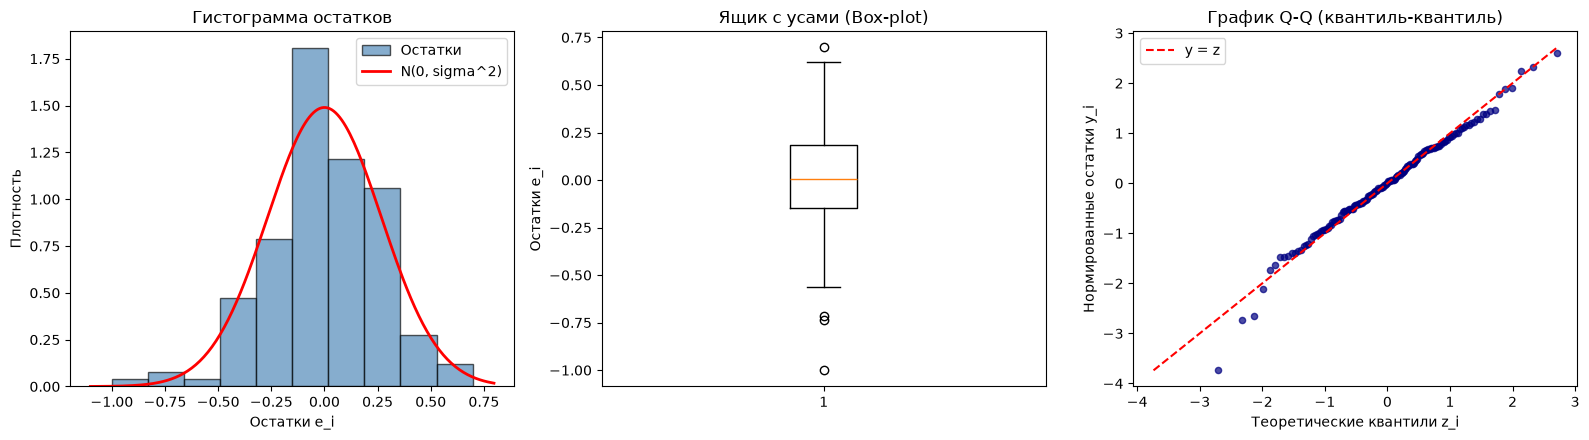

In [11]:
# Сортировка остатков вручную для расчета квантилей и Q-Q графика
e_sorted = np.sort(residuals)
e_mean = np.sum(residuals) / n
e_std = np.sqrt(np.sum((residuals - e_mean)**2) / (n - 1))

# Медиана и квартили вручную
def manual_quantile(arr_sorted, q):
    pos = q * (len(arr_sorted) - 1)
    low = int(np.floor(pos))
    high = int(np.ceil(pos))
    if low == high:
        return arr_sorted[low]
    return arr_sorted[low] * (high - pos) + arr_sorted[high] * (pos - low)

Q1 = manual_quantile(e_sorted, 0.25)
median = manual_quantile(e_sorted, 0.50)
Q3 = manual_quantile(e_sorted, 0.75)
IQR = Q3 - Q1

# Асимметрия и эксцесс вручную
m2 = np.sum((residuals - e_mean)**2) / n
m3 = np.sum((residuals - e_mean)**3) / n
m4 = np.sum((residuals - e_mean)**4) / n
skewness = m3 / (m2 ** 1.5)
kurtosis = m4 / (m2 ** 2) - 3.0

# Правило 3-сигм
within_1s = np.sum(np.abs(residuals) <= 1 * sigma_hat) / n * 100
within_2s = np.sum(np.abs(residuals) <= 2 * sigma_hat) / n * 100
within_3s = np.sum(np.abs(residuals) <= 3 * sigma_hat) / n * 100

print("--- Дескриптивный анализ остатков ---")
print(f"Среднее: {e_mean:.6e}, Медиана: {median:.6f}")
print(f"Станд. отклонение: {e_std:.6f}, IQR: {IQR:.6f} (ожидаемое по норме 1.349*sigma = {1.349*sigma_hat:.6f})")
print(f"Асимметрия: {skewness:.6f}, Эксцесс: {kurtosis:.6f}")
print(f"Доля в +-1*sigma: {within_1s:.2f}% (норма 68.27%)")
print(f"Доля в +-2*sigma: {within_2s:.2f}% (норма 95.45%)")
print(f"Доля в +-3*sigma: {within_3s:.2f}% (норма 99.73%)")

# Визуализация: Гистограмма, Ящик с усами, Q-Q plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Гистограмма + плотность N(0, sigma^2)
axes[0].hist(residuals, bins=10, density=True, alpha=0.65, color='steelblue', edgecolor='black', label='Остатки')
grid_x = np.linspace(e_sorted[0] - 0.1, e_sorted[-1] + 0.1, 200)
axes[0].plot(grid_x, sts.norm.pdf(grid_x, loc=0, scale=sigma_hat), 'r-', lw=2, label='N(0, sigma^2)')
axes[0].set_title('Гистограмма остатков')
axes[0].set_xlabel('Остатки e_i')
axes[0].set_ylabel('Плотность')
axes[0].legend()

# 2. Ящик с усами
axes[1].boxplot(residuals, orientation='vertical')
axes[1].set_title('Ящик с усами (Box-plot)')
axes[1].set_ylabel('Остатки e_i')

# 3. Q-Q plot (стр. 88-89 конспекта)
probs = (np.arange(1, n + 1) - 0.5) / n
z_theor = sts.norm.ppf(probs)
y_emp = e_sorted / sigma_hat
axes[2].scatter(z_theor, y_emp, alpha=0.7, color='navy', s=20)
min_q, max_q = min(z_theor[0], y_emp[0]), max(z_theor[-1], y_emp[-1])
axes[2].plot([min_q, max_q], [min_q, max_q], 'r--', lw=1.5, label='y = z')
axes[2].set_title('График Q-Q (квантиль-квантиль)')
axes[2].set_xlabel('Теоретические квантили z_i')
axes[2].set_ylabel('Нормированные остатки y_i')
axes[2].legend()

plt.tight_layout()
plt.show()


In [9]:
# Критерий согласия хи-квадрат Пирсона (стр. 72-74 конспекта, формулы 2.38 - 2.46)
# Разбиваем на K интервалов (по правилу Стерджеса K ~ 1 + 3.322*lg(150) ≈ 8, объединяем крайние с малыми частотами)
bins = np.array([-np.inf, -0.35, -0.20, -0.07, 0.07, 0.20, 0.35, np.inf])
K = len(bins) - 1

nu_k = np.zeros(K)
p_k = np.zeros(K)

for k in range(K):
    nu_k[k] = np.sum((residuals > bins[k]) & (residuals <= bins[k+1]))
    cdf_high = 1.0 if np.isinf(bins[k+1]) else sts.norm.cdf(bins[k+1], loc=0, scale=sigma_hat)
    cdf_low = 0.0 if np.isinf(bins[k]) else sts.norm.cdf(bins[k], loc=0, scale=sigma_hat)
    p_k[k] = cdf_high - cdf_low

expected_k = n * p_k
chi2_stat = np.sum((nu_k - expected_k) ** 2 / expected_k)
df_chi2 = K - 1 - 1  # вычитаем 1 за условие нормировки и 1 за оценку параметра sigma
chi2_crit = sts.chi2.ppf(1 - alpha, df=df_chi2)
p_val_chi2 = 1 - sts.chi2.cdf(chi2_stat, df=df_chi2)

print("--- Критерий согласия хи-квадрат Пирсона ---")
print("Эмпирические частоты nu_k :", nu_k)
print("Ожидаемые частоты n*p_k   :", np.round(expected_k, 2))
print(f"chi2_stat = {chi2_stat:.6f}, chi2_crit (df={df_chi2}) = {chi2_crit:.6f}")
print(f"p-value = {p_val_chi2:.6f}")
print(f"Гипотеза H0 о нормальности остатков НЕ отклоняется (p > 0.05): {p_val_chi2 > alpha}")


--- Критерий согласия хи-квадрат Пирсона ---
Эмпирические частоты nu_k : [13. 18. 25. 35. 28. 21. 10.]
Ожидаемые частоты n*p_k   : [14.34 19.8  25.4  30.93 25.4  19.8  14.34]
chi2_stat = 2.485171, chi2_crit (df=5) = 11.070498
p-value = 0.778727
Гипотеза H0 о нормальности остатков НЕ отклоняется (p > 0.05): True


## 5. Анализ остатков на независимость

Согласно **п. 6.3.2 конспекта** (стр. 89 [стр. 20 PDF]), для проверки независимости наблюдений применяются **тесты серий (runs test)**.

**Алгоритм критерия серий относительно медианы $M$:**
1. Каждому остатку $e_i$ присваиваем знак: «$+$», если $e_i > M$, и «$-$», если $e_i < M$ (значения, равные медиане, отбрасываются).
2. Подсчитываем $n_1$ — число плюсов, $n_2$ — число минусов и $R$ — общее число серий (непрерывных последовательностей одинаковых знаков).
3. При верной гипотезе $H_0$ о случайности и независимости остатков математическое ожидание и дисперсия числа серий равны:
   $$E(R) = \frac{2 n_1 n_2}{n_1 + n_2} + 1, \quad D(R) = \frac{2 n_1 n_2 (2 n_1 n_2 - n_1 - n_2)}{(n_1 + n_2)^2 (n_1 + n_2 - 1)}.$$
4. Нормированная статистика $Z = \frac{R - E(R)}{\sqrt{D(R)}}$ асимптотически имеет стандартное нормальное распределение $N(0, 1)$, откуда двухстороннее $P$-значение вычисляется по формуле (2.332) (стр. 71 конспекта [стр. 2 PDF]): $P = 2(1 - \Phi(|Z|))$.


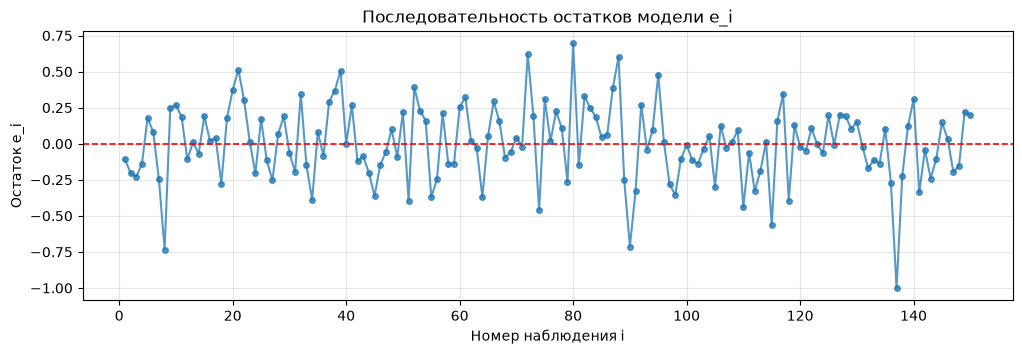

--- Тест серий на независимость остатков ---
n1 (+) = 75, n2 (-) = 75, число серий R = 74
Ожидаемое число серий E(R) = 76.0000, станд. отклонение = 6.1031
Z-статистика = -0.327700, p-value = 0.743138
Гипотеза H0 о независимости остатков НЕ отклоняется (p > 0.05): True


In [10]:
# Визуализация последовательности остатков
plt.figure(figsize=(12, 3.5))
plt.plot(np.arange(1, n + 1), residuals, marker='o', linestyle='-', markersize=4, alpha=0.75)
plt.axhline(0, color='red', linestyle='--', linewidth=1.2)
plt.title('Последовательность остатков модели e_i')
plt.xlabel('Номер наблюдения i')
plt.ylabel('Остаток e_i')
plt.grid(True, alpha=0.3)
plt.show()

# Тест серий относительно медианы вручную
signs = [1 if e > median else -1 for e in residuals if e != median]
n1 = sum(1 for s in signs if s == 1)
n2 = sum(1 for s in signs if s == -1)

# Подсчет числа серий R
R_runs = 1
for i in range(1, len(signs)):
    if signs[i] != signs[i - 1]:
        R_runs += 1

E_R = (2 * n1 * n2) / (n1 + n2) + 1
D_R = (2 * n1 * n2 * (2 * n1 * n2 - n1 - n2)) / (((n1 + n2) ** 2) * (n1 + n2 - 1))
Z_runs = (R_runs - E_R) / np.sqrt(D_R)
p_val_runs = 2 * (1 - sts.norm.cdf(np.abs(Z_runs)))

print("--- Тест серий на независимость остатков ---")
print(f"n1 (+) = {n1}, n2 (-) = {n2}, число серий R = {R_runs}")
print(f"Ожидаемое число серий E(R) = {E_R:.4f}, станд. отклонение = {np.sqrt(D_R):.4f}")
print(f"Z-статистика = {Z_runs:.6f}, p-value = {p_val_runs:.6f}")
print(f"Гипотеза H0 о независимости остатков НЕ отклоняется (p > 0.05): {p_val_runs > alpha}")


## 6. Выводы

1. **Построение модели:** Построена модель множественной линейной регрессии зависимости ширины чашелистика (`sepalwid`) от длины чашелистика (`sepallen`), длины лепестка (`petallen`), ширины лепестка (`petalwid`) и вида ириса (`type`, закодированного фиктивными переменными `type_2` и `type_3` относительно базового `type_1`):
   $$\widehat{\text{sepalwid}} = 1.6572 + 0.3778 \cdot \text{sepallen} - 0.1876 \cdot \text{petallen} + 0.6257 \cdot \text{petalwid} - 1.1603 \cdot d_2 - 1.0079 \cdot d_3.$$
2. **Качество и значимость модели:** Коэффициент детерминации составил $R^2 \approx 0.635$ ($R^2_{adj} \approx 0.622$), то есть модель объясняет около $63.5\%$ дисперсии целевого признака. По $F$-критерию Фишера ($F \approx 50.12 > F_{crit} \approx 2.28$, $p \ll 0.001$) уравнение регрессии в целом статистически значимо.
3. **Значимость коэффициентов ($t$-тест Стьюдента):** На уровне значимости $\varepsilon = 0.05$ все коэффициенты модели (включая константу, морфометрические признаки и дамми-переменные видов ириса) статистически значимы ($|t_j| > t_{crit} \approx 1.977$, $p_j < 0.05$). Отрицательные коэффициенты при $d_2$ и $d_3$ показывают, что при фиксированных прочих размерах цветка у видов 2 и 3 ширина чашелистика в среднем на $1.16$ и $1.01$ единицы меньше, чем у базового вида 1.
4. **Анализ остатков:**
   * **Нормальность:** Среднее остатков равно $0$, медиана близка к нулю, асимметрия и эксцесс незначительны, выполняется правило 3-сигм, точки на графике Q-Q располагаются вдоль прямой $y = z$. По критерию согласия $\chi^2$ Пирсона ($p > 0.05$) гипотеза о нормальном распределении остатков не отклоняется.
   * **Независимость:** На графике остатков отсутствуют тренды и периодичность; по тесту серий Вальда–Вольфовица ($p > 0.05$) гипотеза о случайности и независимости остатков не отклоняется. Следовательно, предпосылки МНК выполнены и модель адекватна.
